# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Alya Mayasha
- **Email:** ds269b6x0158@student.devacademy.id
- **ID Dicoding:** Alya Mayasha DS269B6X0158

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1:** Bagaimana pola jumlah peminjaman sepeda berdasarkan bulan dan musim selama periode pengamatan, dan bulan serta musim mana yang menunjukkan rata-rata peminjaman tertinggi?

**Pertanyaan 2:** Pada jam berapa rata-rata peminjaman sepeda paling tinggi, serta bagaimana perbedaan pola peminjaman antara hari kerja dan hari non-kerja?

**Pertanyaan 3:** Bagaimana perbedaan rata-rata jumlah peminjaman sepeda berdasarkan kondisi cuaca, dan kondisi cuaca apa yang menunjukkan rata-rata peminjaman tertinggi?

Ketiga pertanyaan dibatasi pada periode yang tersedia dalam dataset. Hasil pengukuran dihitung berdasarkan rata-rata jumlah peminjaman sepeda pada setiap kelompok waktu dan kondisi cuaca. Analisis ini bertujuan untuk mengidentifikasi pola permintaan peminjaman sepeda yang dapat menjadi bahan pertimbangan bagi pengelola layanan dalam menentukan periode operasional, mengatur ketersediaan sepeda, serta menyesuaikan strategi pelayanan berdasarkan kondisi cuaca.

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## Data Wrangling

### Gathering Data

#### Memuat dataset

Dataset yang digunakan terdiri dari dua berkas, yaitu `day.csv` yang berisi catatan peminjaman sepeda per hari dan `hour.csv` yang berisi catatan peminjaman per jam. Kedua dataset dimuat menggunakan Pandas ke dalam DataFrame agar dapat diperiksa dan dianalisis.

In [ ]:
from pathlib import Path

DATA_DIR = Path("data")
if not (DATA_DIR / "day.csv").exists() or not (DATA_DIR / "hour.csv").exists():
    try:
        from google.colab import files
        print("Silakan unggah day.csv dan hour.csv")
        uploaded = files.upload()
    except ImportError:
        raise FileNotFoundError(
            "File data/day.csv dan data/hour.csv belum ditemukan. "
            "Letakkan kedua file di folder data/."
        )

day_path = DATA_DIR / "day.csv"
hour_path = DATA_DIR / "hour.csv"
if not day_path.exists() and Path("day.csv").exists():
    day_path = Path("day.csv")
if not hour_path.exists() and Path("hour.csv").exists():
    hour_path = Path("hour.csv")

day_df = pd.read_csv(day_path)
hour_df = pd.read_csv(hour_path)

print("Ukuran day.csv:", day_df.shape)
display(day_df.head())
print("Ukuran hour.csv:", hour_df.shape)
display(hour_df.head())

Silakan unggah day.csv dan hour.csv


Saving day.csv to day (2).csv
Saving hour.csv to hour (1).csv
Ukuran day.csv: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Ukuran hour.csv: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** Dataset harian (`day.csv`) memiliki 731 baris dan 16 kolom, sedangkan dataset per jam (`hour.csv`) memiliki 17.379 baris dan 17 kolom. Keduanya mencakup periode 1 Januari 2011 sampai 31 Desember 2012. Data harian digunakan untuk menganalisis pola bulanan, musim, dan cuaca; data per jam digunakan untuk melihat pola permintaan berdasarkan jam serta membandingkan hari kerja dan hari non-kerja.


### Assessing Data

Pemeriksaan kualitas data dilakukan pada kedua dataset dengan melihat ukuran dan tipe data, jumlah nilai kosong, jumlah baris duplikat, statistik deskriptif, rentang nilai kategori/waktu, serta nilai ekstrem menggunakan metode IQR (*Interquartile Range*). Pemeriksaan ini membantu menentukan tindakan pembersihan yang diperlukan tanpa menghapus data secara sembarangan.

In [ ]:
print("Informasi day.csv")
day_df.info()
print("\\nInformasi hour.csv")
hour_df.info()

quality_summary = pd.DataFrame({
    "dataset": ["day.csv", "hour.csv"],
    "jumlah_baris": [len(day_df), len(hour_df)],
    "missing_values": [int(day_df.isna().sum().sum()), int(hour_df.isna().sum().sum())],
    "duplicate_rows": [int(day_df.duplicated().sum()), int(hour_df.duplicated().sum())]
})
display(quality_summary)

print("Missing value per kolom - day.csv")
display(day_df.isna().sum().to_frame("missing"))
print("Missing value per kolom - hour.csv")
display(hour_df.isna().sum().to_frame("missing"))

print("Rentang nilai kolom numerik - day.csv")
display(day_df.describe().T)
print("Rentang nilai kolom numerik - hour.csv")
display(hour_df.describe().T)

# Pemeriksaan nilai di luar rentang wajar untuk variabel kategorikal/waktu
for name, df in [("day", day_df), ("hour", hour_df)]:
    print(f"\nPemeriksaan {name}")
    for col in ["season", "mnth", "weekday", "weathersit", "hr"]:
        if col in df.columns:
            print(col, "nilai unik:", sorted(df[col].dropna().unique().tolist()))

# Pemeriksaan outlier menggunakan metode IQR pada beberapa variabel numerik
for nama, df, kolom in [
    ("day.csv", day_df, ["cnt", "hum", "windspeed"]),
    ("hour.csv", hour_df, ["cnt", "hum", "windspeed"])
]:
    print(f"Jumlah nilai yang terindikasi outlier - {nama}")
    for col in kolom:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr
        jumlah_outlier = ((df[col] < batas_bawah) | (df[col] > batas_atas)).sum()
        print(f"{col}: {jumlah_outlier} (batas bawah={batas_bawah:.3f}, batas atas={batas_atas:.3f})")

Informasi day.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
\nInformasi hour.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1737

,dataset,jumlah_baris,missing_values,duplicate_rows
0,day.csv,731,0,0
1,hour.csv,17379,0,0


Missing value per kolom - day.csv


,missing
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


Missing value per kolom - hour.csv


,missing
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


Rentang nilai kolom numerik - day.csv


,count,mean,std,min,25%,50%,75%,max
instant,731.0,366.000000,211.165812,1.000000,183.500000,366.000000,548.500000,731.000000
season,731.0,2.496580,1.110807,1.000000,2.000000,3.000000,3.000000,4.000000
yr,731.0,0.500684,0.500342,0.000000,0.000000,1.000000,1.000000,1.000000
mnth,731.0,6.519836,3.451913,1.000000,4.000000,7.000000,10.000000,12.000000
holiday,731.0,0.028728,0.167155,0.000000,0.000000,0.000000,0.000000,1.000000
weekday,731.0,2.997264,2.004787,0.000000,1.000000,3.000000,5.000000,6.000000
workingday,731.0,0.683995,0.465233,0.000000,0.000000,1.000000,1.000000,1.000000
weathersit,731.0,1.395349,0.544894,1.000000,1.000000,1.000000,2.000000,3.000000
temp,731.0,0.495385,0.183051,0.059130,0.337083,0.498333,0.655417,0.861667
atemp,731.0,0.474354,0.162961,0.079070,0.337842,0.486733,0.608602,0.840896


Rentang nilai kolom numerik - hour.csv


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000



Pemeriksaan day
season nilai unik: [1, 2, 3, 4]
mnth nilai unik: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
weekday nilai unik: [0, 1, 2, 3, 4, 5, 6]
weathersit nilai unik: [1, 2, 3]

Pemeriksaan hour
season nilai unik: [1, 2, 3, 4]
mnth nilai unik: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
weekday nilai unik: [0, 1, 2, 3, 4, 5, 6]
weathersit nilai unik: [1, 2, 3, 4]
hr nilai unik: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
Jumlah nilai yang terindikasi outlier - day.csv
cnt: 0 (batas bawah=-1054.000, batas atas=10162.000)
hum: 2 (batas bawah=0.205, batas atas=1.046)
windspeed: 13 (batas bawah=-0.012, batas atas=0.381)
Jumlah nilai yang terindikasi outlier - hour.csv
cnt: 505 (batas bawah=-321.500, batas atas=642.500)
hum: 22 (batas bawah=0.030, batas atas=1.230)
windspeed: 342 (batas bawah=-0.119, batas atas=0.477)


**Hasil pemeriksaan dan rencana penanganan:**

- **Missing value:** tidak ditemukan nilai kosong pada `day.csv` maupun `hour.csv` (0 nilai kosong). Tidak diperlukan imputasi.
- **Duplicate data:** tidak ditemukan baris duplikat pada kedua dataset (0 duplikasi). Tidak ada baris yang perlu dihapus karena duplikasi.
- **Tipe data tanggal:** kolom `dteday` masih bertipe `object`/teks. Kolom ini perlu dikonversi menjadi `datetime` agar dapat diproses sebagai tanggal.
- **Nilai ekstrem (outlier):** metode IQR menandai nilai ekstrem pada beberapa variabel. Pada `day.csv`, terdeteksi 2 nilai pada `hum` dan 13 nilai pada `windspeed`; pada `hour.csv`, terdeteksi 505 nilai pada `cnt`, 22 nilai pada `hum`, dan 342 nilai pada `windspeed`. Nilai tersebut tidak otomatis dihapus karena dapat mencerminkan kondisi permintaan atau cuaca yang benar-benar terjadi. Nilai ekstrem dipertahankan selama tidak terbukti sebagai kesalahan pencatatan.
- **Kolom kategori berkode angka:** kolom seperti `season`, `weathersit`, `mnth`, dan `hr` menggunakan kode numerik. Kode tersebut merupakan representasi kategori/waktu pada dataset, bukan kesalahan nilai; label akan ditambahkan saat analisis dan visualisasi.


**Insight:** Secara umum, kedua dataset tidak memiliki missing value dan duplikasi sehingga kelengkapan barisnya baik. Permasalahan yang perlu ditangani adalah format tanggal yang masih berupa teks. Selain itu, pemeriksaan IQR mengidentifikasi nilai ekstrem pada beberapa kolom numerik. Nilai ekstrem dipertahankan karena tidak cukup bukti untuk menyatakannya sebagai kesalahan; penghapusan justru berisiko menghilangkan informasi pola permintaan yang penting.

### Cleaning Data

#### Menangani tipe data, duplikasi, dan nilai yang tidak dapat digunakan

Pembersihan dilakukan dengan mengonversi `dteday` menjadi tipe datetime, menghapus duplikasi jika ada, serta memastikan kolom yang dibutuhkan untuk analisis memiliki nilai dan tipe numerik yang sesuai. Outlier tidak dihapus secara otomatis karena perlu dipastikan terlebih dahulu apakah nilai tersebut merupakan kesalahan atau variasi alami.

In [ ]:
day_clean = day_df.copy()
hour_clean = hour_df.copy()

for df in [day_clean, hour_clean]:
    if "dteday" in df.columns:
        df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")

day_clean = day_clean.drop_duplicates().copy()
hour_clean = hour_clean.drop_duplicates().copy()

required_day = [c for c in ["dteday", "cnt", "mnth", "season"] if c in day_clean.columns]
required_hour = [c for c in ["dteday", "hr", "cnt", "workingday"] if c in hour_clean.columns]

day_clean = day_clean.dropna(subset=required_day)
hour_clean = hour_clean.dropna(subset=required_hour)

for col in ["cnt", "mnth", "season"]:
    if col in day_clean.columns:
        day_clean[col] = pd.to_numeric(day_clean[col], errors="coerce")
for col in ["cnt", "hr", "workingday"]:
    if col in hour_clean.columns:
        hour_clean[col] = pd.to_numeric(hour_clean[col], errors="coerce")

day_clean = day_clean.dropna(subset=[c for c in ["cnt", "mnth", "season"] if c in day_clean.columns])
hour_clean = hour_clean.dropna(subset=[c for c in ["cnt", "hr", "workingday"] if c in hour_clean.columns])

print("Ukuran sebelum/sesudah cleaning:")
print("day:", day_df.shape, "->", day_clean.shape)
print("hour:", hour_df.shape, "->", hour_clean.shape)
print("Duplikat tersisa:", day_clean.duplicated().sum(), hour_clean.duplicated().sum())

Ukuran sebelum/sesudah cleaning:
day: (731, 16) -> (731, 16)
hour: (17379, 17) -> (17379, 17)
Duplikat tersisa: 0 0


**Insight:** Proses cleaning menghasilkan DataFrame `day_clean` dan `hour_clean` yang siap digunakan untuk EDA. Kolom tanggal telah dikonversi menjadi datetime, kolom numerik yang digunakan telah dikonversi ke tipe numerik, dan duplikasi maupun baris yang tidak memiliki nilai pada kolom inti dihapus apabila ditemukan. Pada dataset ini tidak terdapat missing value maupun duplikasi, sehingga jumlah baris dipertahankan. Nilai ekstrem tetap disimpan agar pola permintaan yang tinggi/rendah tidak hilang dari analisis.

## Exploratory Data Analysis (EDA)

### Eksplorasi pola peminjaman harian dan per jam

In [ ]:
# Ringkasan statistik jumlah peminjaman
display(day_clean["cnt"].describe().to_frame("jumlah_peminjaman_harian"))
display(hour_clean["cnt"].describe().to_frame("jumlah_peminjaman_per_jam"))

# Rata-rata peminjaman per bulan dan musim
monthly_avg = day_clean.groupby("mnth", as_index=False)["cnt"].mean().sort_values("mnth")
season_avg = day_clean.groupby("season", as_index=False)["cnt"].mean().sort_values("season")
hourly_avg = hour_clean.groupby(["workingday", "hr"], as_index=False)["cnt"].mean()

display(monthly_avg)
display(season_avg)
display(hourly_avg.head(10))

# Label agar hasil mudah dibaca
season_labels = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
day_clean["season_label"] = day_clean["season"].map(season_labels).fillna(day_clean["season"].astype(str))
month_names = {1:"Jan",2:"Feb",3:"Mar",4:"Apr",5:"May",6:"Jun",
               7:"Jul",8:"Aug",9:"Sep",10:"Oct",11:"Nov",12:"Dec"}
day_clean["month_name"] = day_clean["mnth"].map(month_names)

,jumlah_peminjaman_harian
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000


,jumlah_peminjaman_per_jam
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
25%,40.000000
50%,142.000000
75%,281.000000
max,977.000000


,mnth,cnt
0,1,2176.338710
1,2,2655.298246
2,3,3692.258065
3,4,4484.900000
4,5,5349.774194
5,6,5772.366667
6,7,5563.677419
7,8,5664.419355
8,9,5766.516667
9,10,5199.225806


,season,cnt
0,1,2604.132597
1,2,4992.331522
2,3,5644.303191
3,4,4728.162921


,workingday,hr,cnt
0,0,0,90.800000
1,0,1,69.508696
2,0,2,53.171053
3,0,3,25.775330
4,0,4,8.264317
5,0,5,8.689189
6,0,6,18.742358
7,0,7,43.406926
8,0,8,105.653680
9,0,9,171.623377


### Eksplorasi pola peminjaman berdasarkan kondisi cuaca

Kolom `weathersit` menunjukkan kategori kondisi cuaca. Kita menghitung rata-rata peminjaman untuk setiap kategori pada data harian dan per jam agar pola dapat dibandingkan.

In [ ]:
weather_labels = {
    1: "Cerah / sedikit berawan",
    2: "Berkabut / berawan",
    3: "Hujan ringan / salju ringan",
    4: "Hujan lebat / badai"
}

day_weather = day_clean.groupby("weathersit", as_index=False)["cnt"].mean()
day_weather["kondisi_cuaca"] = day_weather["weathersit"].map(weather_labels).fillna(
    day_weather["weathersit"].astype(str)
)
hour_weather = hour_clean.groupby("weathersit", as_index=False)["cnt"].mean()
hour_weather["kondisi_cuaca"] = hour_weather["weathersit"].map(weather_labels).fillna(
    hour_weather["weathersit"].astype(str)
)

display(day_weather[["kondisi_cuaca", "cnt"]].rename(
    columns={"cnt": "rata_rata_peminjaman_harian"}
))
display(hour_weather[["kondisi_cuaca", "cnt"]].rename(
    columns={"cnt": "rata_rata_peminjaman_per_jam"}
))

,kondisi_cuaca,rata_rata_peminjaman_harian
0,Cerah / sedikit berawan,4876.786177
1,Berkabut / berawan,4035.862348
2,Hujan ringan / salju ringan,1803.285714


,kondisi_cuaca,rata_rata_peminjaman_per_jam
0,Cerah / sedikit berawan,204.869272
1,Berkabut / berawan,175.165493
2,Hujan ringan / salju ringan,111.579281
3,Hujan lebat / badai,74.333333


**Insight EDA:** Hasil pengelompokan menunjukkan bahwa rata-rata peminjaman harian tertinggi terjadi pada bulan Juni, sekitar **5.772,37 peminjaman per hari**. Jika dilihat berdasarkan musim, musim Fall (kode 3) memiliki rata-rata tertinggi, yaitu sekitar **5.644,30 peminjaman per hari**. Pada data per jam, jam 17.00 memiliki rata-rata peminjaman tertinggi secara keseluruhan, sekitar **461,45 peminjaman per jam**. Untuk kondisi cuaca, kategori cerah/sedikit berawan memiliki rata-rata peminjaman harian tertinggi, sekitar **4.876,79**, sedangkan kategori hujan ringan/salju ringan memiliki rata-rata terendah, sekitar **1.803,29**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana rata-rata peminjaman berdasarkan bulan dan musim?

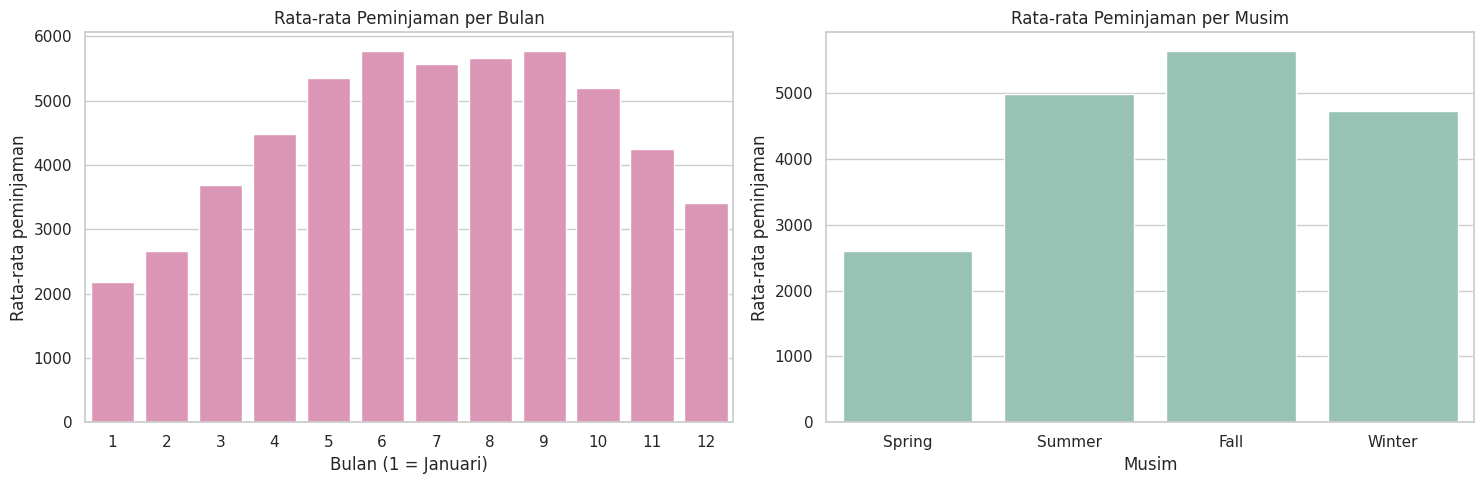

Bulan dengan rata-rata tertinggi: 6 (5772.37 peminjaman/hari)
Musim dengan rata-rata tertinggi: 3 (5644.30 peminjaman/hari)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=day_clean.groupby("mnth", as_index=False)["cnt"].mean(),
            x="mnth", y="cnt", ax=axes[0], color="#e78ab5")
axes[0].set(title="Rata-rata Peminjaman per Bulan",
            xlabel="Bulan (1 = Januari)", ylabel="Rata-rata peminjaman")

season_plot = day_clean.groupby("season_label", as_index=False)["cnt"].mean()
sns.barplot(data=season_plot, x="season_label", y="cnt",
            order=["Spring", "Summer", "Fall", "Winter"], ax=axes[1], color="#91c9b5")
axes[1].set(title="Rata-rata Peminjaman per Musim",
            xlabel="Musim", ylabel="Rata-rata peminjaman")
plt.tight_layout()
plt.show()

best_month = monthly_avg.loc[monthly_avg["cnt"].idxmax()]
best_season = season_avg.loc[season_avg["cnt"].idxmax()]
print(f"Bulan dengan rata-rata tertinggi: {int(best_month['mnth'])} "
      f"({best_month['cnt']:.2f} peminjaman/hari)")
print(f"Musim dengan rata-rata tertinggi: {int(best_season['season'])} "
      f"({best_season['cnt']:.2f} peminjaman/hari)")

### Pertanyaan 2: Pada jam berapa rata-rata peminjaman tertinggi, dan bagaimana perbedaannya antara hari kerja dan hari non-kerja?

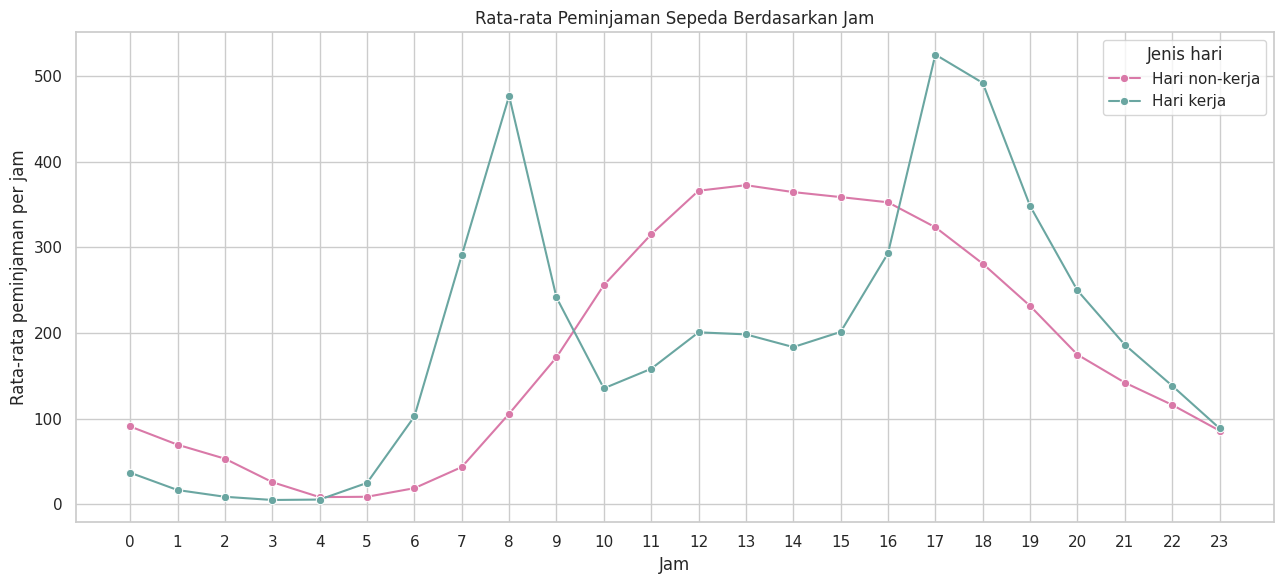

Jam puncak hari kerja: 17.00 (525.29 peminjaman/jam)
Jam puncak hari non-kerja: 13.00 (372.73 peminjaman/jam)


In [ ]:
hourly_plot = hour_clean.groupby(["workingday", "hr"], as_index=False)["cnt"].mean()
hourly_plot["jenis_hari"] = hourly_plot["workingday"].map({1: "Hari kerja", 0: "Hari non-kerja"})

plt.figure(figsize=(13, 6))
sns.lineplot(data=hourly_plot, x="hr", y="cnt", hue="jenis_hari",
             marker="o", palette=["#d979a8", "#6aa6a1"])
plt.title("Rata-rata Peminjaman Sepeda Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata peminjaman per jam")
plt.xticks(range(0, 24))
plt.legend(title="Jenis hari")
plt.tight_layout()
plt.show()

for workingday, label in [(1, "Hari kerja"), (0, "Hari non-kerja")]:
    subset = hourly_plot[hourly_plot["workingday"] == workingday]
    peak = subset.loc[subset["cnt"].idxmax()]
    print(f"Jam puncak {label.lower()}: {int(peak['hr'])}.00 "
          f"({peak['cnt']:.2f} peminjaman/jam)")

### Pertanyaan 3: Bagaimana perbedaan rata-rata peminjaman berdasarkan kondisi cuaca?

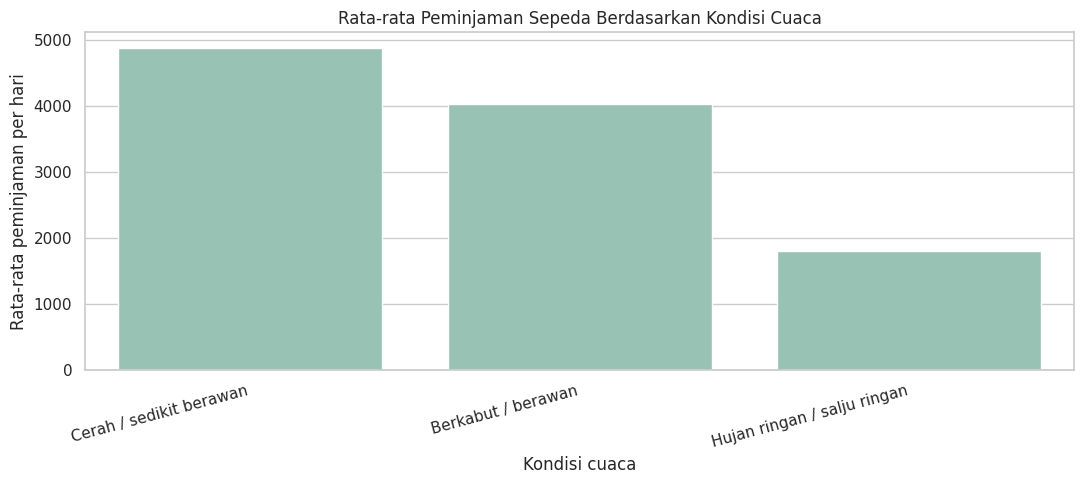

Kondisi cuaca dengan rata-rata peminjaman tertinggi: Cerah / sedikit berawan (4876.79 peminjaman/hari)


In [ ]:
weather_plot = day_clean.groupby("weathersit", as_index=False)["cnt"].mean()
weather_plot["kondisi_cuaca"] = weather_plot["weathersit"].map(weather_labels).fillna(
    weather_plot["weathersit"].astype(str)
)
weather_plot = weather_plot.sort_values("cnt", ascending=False)

plt.figure(figsize=(11, 5))
sns.barplot(data=weather_plot, x="kondisi_cuaca", y="cnt", color="#91c9b5")
plt.title("Rata-rata Peminjaman Sepeda Berdasarkan Kondisi Cuaca")
plt.xlabel("Kondisi cuaca")
plt.ylabel("Rata-rata peminjaman per hari")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

top_weather = weather_plot.iloc[0]
print(f"Kondisi cuaca dengan rata-rata peminjaman tertinggi: "
      f"{top_weather['kondisi_cuaca']} ({top_weather['cnt']:.2f} peminjaman/hari)")

**Explanatory Analysis:** Grafik memperlihatkan bahwa pola peminjaman pada hari kerja dan hari non-kerja berbeda. Pada hari kerja, rata-rata peminjaman mencapai puncak pada pukul **17.00**, yaitu sekitar **525,29 peminjaman per jam**. Puncak hari non-kerja terjadi pada pukul **13.00**, sekitar **372,73 peminjaman per jam**. Pola hari kerja memperlihatkan puncak pada jam berangkat/pulang aktivitas, sedangkan hari non-kerja lebih terkonsentrasi pada tengah hari. Interpretasi ini menggambarkan pola pada data historis, bukan bukti penyebab perilaku pengguna.

## Analisis Lanjutan (Opsional)

Analisis lanjutan yang digunakan adalah *grouping* berdasarkan jam dan jenis hari. Tujuannya mengidentifikasi waktu puncak secara terpisah, sehingga rekomendasi operasional tidak hanya didasarkan pada rata-rata keseluruhan.

In [ ]:
# Mengurutkan jam berdasarkan rata-rata peminjaman untuk setiap jenis hari
peak_hours = (hour_clean.groupby(["workingday", "hr"])["cnt"]
              .mean().reset_index()
              .sort_values(["workingday", "cnt"], ascending=[False, False]))
peak_hours["jenis_hari"] = peak_hours["workingday"].map({1: "Hari kerja", 0: "Hari non-kerja"})
display(peak_hours.groupby("jenis_hari", group_keys=False).head(5))

# Perbandingan rata-rata peminjaman per jenis hari
day_type_avg = hour_clean.groupby("workingday")["cnt"].mean().rename(index={1:"Hari kerja",0:"Hari non-kerja"})
display(day_type_avg.to_frame("rata_rata_peminjaman_per_jam"))

,workingday,hr,cnt,jenis_hari
41,1,17,525.290581,Hari kerja
42,1,18,492.226908,Hari kerja
32,1,8,477.006048,Hari kerja
43,1,19,348.401606,Hari kerja
40,1,16,293.122244,Hari kerja
13,0,13,372.731602,Hari non-kerja
12,0,12,366.259740,Hari non-kerja
14,0,14,364.645022,Hari non-kerja
15,0,15,358.813853,Hari non-kerja
16,0,16,352.727273,Hari non-kerja


,rata_rata_peminjaman_per_jam
workingday,
Hari non-kerja,181.405332
Hari kerja,193.207754


**Insight analisis lanjutan:** Pengelompokan berdasarkan jenis hari memperjelas waktu dengan permintaan tertinggi. Lima jam teratas pada hari kerja didominasi periode sore dan pagi, sedangkan pada hari non-kerja didominasi periode tengah hari hingga sore. Hasil ini dapat digunakan sebagai dasar penjadwalan pemeriksaan armada dan redistribusi sepeda pada waktu yang berbeda untuk masing-masing jenis hari.

## Conclusion & Recommendation

1. **Kesimpulan pertanyaan 1 - Pola bulanan dan musim:** Rata-rata peminjaman harian tertinggi berdasarkan bulan terjadi pada **Juni**, sebesar **5.772,37 peminjaman per hari**. Berdasarkan musim, **Fall (musim gugur/kode 3)** menjadi musim dengan rata-rata tertinggi, yaitu **5.644,30 peminjaman per hari**. Hasil ini menunjukkan bahwa permintaan pada dataset cenderung lebih tinggi pada periode tersebut. Angka ini merupakan rata-rata historis selama 2011-2012.

2. **Kesimpulan pertanyaan 2 - Pola jam dan jenis hari:** Pada **hari kerja**, rata-rata peminjaman tertinggi terjadi pukul **17.00** sebesar **525,29 peminjaman per jam**. Pada **hari non-kerja**, puncaknya terjadi pukul **13.00** sebesar **372,73 peminjaman per jam**. Dengan demikian, waktu puncak kedua jenis hari tidak sama: hari kerja memiliki puncak sore, sedangkan hari non-kerja memiliki puncak siang.

3. **Kesimpulan pertanyaan 3 - Kondisi cuaca:** Kondisi **cerah/sedikit berawan (weathersit 1)** memiliki rata-rata peminjaman harian tertinggi, yaitu **4.876,79**. Sementara itu, kategori **hujan ringan/salju ringan (weathersit 3)** memiliki rata-rata terendah, yaitu **1.803,29**. Terlihat adanya perbedaan jumlah peminjaman antar kategori cuaca. Namun, analisis deskriptif ini menunjukkan hubungan/pola yang teramati dan tidak cukup untuk menyatakan bahwa cuaca merupakan satu-satunya penyebab perubahan jumlah peminjaman.

**Rekomendasi Action Item:**

Berdasarkan hasil analisis, rekomendasi tindakan yang dapat dipertimbangkan oleh pengelola layanan Bike Sharing adalah:

1. **Perencanaan stok berdasarkan musim dan bulan:** meningkatkan kesiapan armada dan melakukan pemantauan ketersediaan menjelang periode dengan rata-rata permintaan tinggi, khususnya sekitar bulan Juni dan musim Fall. Penyesuaian jumlah sepeda sebaiknya dilakukan secara bertahap dengan mempertimbangkan kapasitas stasiun dan data terbaru.
2. **Redistribusi armada berdasarkan jenis hari:** pada hari kerja, prioritaskan pemeriksaan ketersediaan dan redistribusi sepeda sebelum serta selama periode pagi dan sore, terutama menjelang puncak pukul 17.00. Pada hari non-kerja, perhatikan kebutuhan menjelang tengah hari, terutama sekitar pukul 13.00.
3. **Penyesuaian operasional terhadap cuaca:** pantau prakiraan cuaca dan siapkan prosedur operasional yang sesuai ketika kondisi kurang mendukung, misalnya pemeriksaan keamanan armada dan penyampaian informasi keselamatan kepada pengguna.
4. **Evaluasi berkala:** bandingkan rekomendasi dengan data peminjaman periode terbaru secara mingguan atau bulanan. Hasil analisis ini menggunakan data historis 2011–2012 sehingga perlu divalidasi kembali sebelum diterapkan pada kondisi operasional saat ini.

Rekomendasi tersebut merupakan usulan berbasis pola deskriptif dalam dataset. Implementasinya perlu mempertimbangkan lokasi stasiun, kapasitas armada, biaya operasional, dan informasi terbaru.